# Modeling: Stent Thrombosis Prediction (VLST) — without leakage

## Overview

This notebook is the leakage-controlled twin of `baseline_tssi_leakage.ipynb`: same models and grids, with the anti-leakage protocol applied (§1). The performance gap between the twins is attributed to **data leakage as a whole**, not to `Time since stent implantation` alone. It trains and evaluates binary classifiers to predict **Stent thrombosis** using the preprocessed data from `../preprocessing/preprocessing.ipynb`. We use:

- **Data**: Preprocessed train/test arrays from `data/processed/` (resolved from repo root; dropped column sliced out in-notebook)
- **Models**: Logistic Regression, Decision Tree, Random Forest, Gaussian NB, CatBoost, XGBoost, LightGBM (with **GridSearchCV** where applicable)
- **Flowcharts**: Fitted GridSearchCV/pipeline objects are displayed so Jupyter shows the interactive sklearn pipeline diagram (expandable flowchart)
- **Imbalance**: Class weights in models (no SMOTE or other oversampling), and metrics suited to imbalanced data (ROC-AUC, AP, F1, recall)
- **Artifacts**: Best models and results saved to `data/result/modeling_no_time_since_stent/` (separate from `baseline_tssi_leakage.ipynb`)

**Leakage comparison arm — ALL LEAKS OFF.** This notebook is the *after* GridSearch under the full anti-leakage system from `baseline_plus_tabpfn.ipynb`: drop `Time since stent implantation` **and** `WBC`, quantize recording-precision labs, stent-brand collapse fit on **train only**, scaler/OHE fit on train only. Twin: `baseline_tssi_leakage.ipynb` keeps all of those leaks.

**Stored outputs in this file (Table S-TSSI “without TSSI”) are the previous processed-npy run** (TSSI sliced out of the npy only). They are kept so reports can still quote them until you re-execute. New runs write to `data/result/modeling_without_tssi/`.



## 1. Setup and Load Preprocessed Data

In [1]:
import numpy as np
import pandas as pd
import os
import joblib
import warnings
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.base import BaseEstimator, ClassifierMixin
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from pathlib import Path
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    f1_score,
    recall_score,
    precision_score,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)

warnings.filterwarnings("ignore")
np.random.seed(42)


def _find_repo_root() -> Path:
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "data" / "raw" / "VLST.csv").is_file():
            return p
    if Path("/kaggle/working").is_dir():
        return Path("/kaggle/working")
    raise FileNotFoundError("Could not locate data/raw/VLST.csv above cwd.")


from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# ---------------------------------------------------------------------------
# Full anti-leakage protocol (same file-level rules as baseline_plus_tabpfn.ipynb).
# The twin (baseline_tssi_leakage.ipynb) keeps TSSI, WBC, raw lab precision, and
# full-cohort stent collapse. This notebook turns all of those off.
# Stored cell outputs / Table S-TSSI below are from the previous npy run; they
# stay until you re-execute. New artifacts go to RESULT_DIR (new folder).
# ---------------------------------------------------------------------------
KEEP_TSSI = False
DROP_WBC = True
QUANTIZE_CLINICAL = True
STENT_ENCODER_TRAIN_ONLY = True
TEST_SIZE = 0.30
RANDOM_STATE = 42
TARGET = "Stent thrombosis"
ID_COLS = ["NO.", "Name"]
STENT_BRAND_COL = "Stent type-SES"
CLINICAL_QUANTIZE_PLACES = {"Cre": 0, "CaI": 2, "Fiberinogen": 1, "Fast-Glu": 1}

DROP_FEATURES = []
if not KEEP_TSSI:
    DROP_FEATURES.append("Time since stent implantation")
if DROP_WBC:
    DROP_FEATURES.append("WBC")


def _discover_vlst_csv(repo: Path) -> Path:
    env = os.environ.get("VLST_RAW_CSV")
    if env and Path(env).is_file():
        return Path(env)
    local = repo / "data" / "raw" / "VLST.csv"
    if local.is_file():
        return local
    for p in (
        Path("/kaggle/input/datasets/amirmahdidaraei/vlst-data/VLST.csv"),
        Path("/kaggle/input/vlst-data/VLST.csv"),
        Path("/kaggle/input/datasets/amirinho661/vlst-figshare-7409606/VLST.csv"),
    ):
        if p.is_file():
            return p
    base = Path("/kaggle/input")
    if base.is_dir():
        for p in base.rglob("VLST.csv"):
            if p.is_file():
                return p
    raise FileNotFoundError("VLST.csv not found.")


def quantize_clinical_precision(frame, places_by_column):
    applied = {}
    for column, places in places_by_column.items():
        if column not in frame.columns or not pd.api.types.is_numeric_dtype(frame[column]):
            continue
        before = pd.to_numeric(frame[column], errors="coerce")
        rounded = before.round(int(places))
        frame[column] = rounded
        applied[column] = {"places": int(places), "n_changed": int((before != rounded).fillna(False).sum())}
    return applied


def _load_stent_encoding():
    import re
    import sys

    search_roots = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    for extra in (Path("/kaggle/working"), Path("/kaggle/input"), Path("/kaggle/usr/lib")):
        if extra.is_dir():
            search_roots.append(extra)
            search_roots.extend(extra.glob("*"))
    for d in search_roots:
        for tools in (d / "code" / "modeling" / "tools", d / "modeling" / "tools", d):
            if (Path(tools) / "stent_encoding.py").is_file():
                tools = Path(tools)
                if str(tools) not in sys.path:
                    sys.path.insert(0, str(tools))
                try:
                    from stent_encoding import (
                        coerce_stent_class_flags,
                        fit_stent_brand_encoder,
                        transform_stent_brand_column,
                    )
                except ImportError:
                    continue
                print("Stent encoder: imported from", tools / "stent_encoding.py")
                return coerce_stent_class_flags, fit_stent_brand_encoder, transform_stent_brand_column

    print("Stent encoder: using in-notebook fallback.")
    STENT_BRAND_MIN_COUNT = 30
    _BRAND_ALIASES = {"xiencex": "xiencev", "resolut": "resolute", "parnter": "partner", "endeavor": "endeavor", "cypher": "cypher"}
    STENT_CLASS_FLAG_COLS = ("PES", "ZES", "EVS")

    def canonicalize_stent_brand(value):
        if pd.isna(value) or str(value).strip() == "":
            return "missing"
        s = str(value).strip().replace("：", ":").lower()
        s = re.sub(r"\s+", "", s)
        if ":" in s:
            s = s.split(":")[-1]
        for sep in ("，", ",", "/"):
            if sep in s:
                s = s.split(sep)[0]
        return _BRAND_ALIASES.get(s, s)

    def coerce_stent_class_flags(df):
        out = df
        for col in STENT_CLASS_FLAG_COLS:
            if col not in out.columns:
                continue
            s = pd.to_numeric(out[col], errors="coerce").fillna(0).astype(int)
            bad = ~s.isin([0, 1])
            if bad.any():
                raise ValueError(f"{col}: expected 0/1, got {out.loc[bad, col].unique()[:10]}")
            out[col] = s
        return out

    def fit_stent_brand_encoder(series, min_count=STENT_BRAND_MIN_COUNT):
        meta = {"min_count": min_count, "numeric": False, "kept": set(), "n_raw": 0, "n_levels": 0, "applied": False}
        if pd.api.types.is_numeric_dtype(series):
            n = int(series.nunique(dropna=True))
            meta.update({"numeric": True, "n_raw": n, "n_levels": n})
            return meta
        canon = series.map(canonicalize_stent_brand)
        counts = canon.value_counts()
        kept = set(counts[counts >= min_count].index)
        meta.update({
            "kept": kept,
            "n_raw": int(series.nunique(dropna=True)),
            "n_levels": int(len(kept) + int((counts < min_count).any())),
            "applied": True,
        })
        return meta

    def transform_stent_brand_column(frame, codebook, raw_col=STENT_BRAND_COL, inplace=False):
        out = frame if inplace else frame.copy()
        if raw_col not in out.columns or codebook.get("numeric") or not codebook.get("applied"):
            return out
        canon = out[raw_col].map(canonicalize_stent_brand)
        kept = codebook["kept"]
        out[raw_col] = canon.where(canon.isin(kept), "other").astype("object")
        return out

    return coerce_stent_class_flags, fit_stent_brand_encoder, transform_stent_brand_column


def encode_stent_on_fold(X_tr, X_va, raw_col=STENT_BRAND_COL, min_count=30):
    if raw_col not in X_tr.columns:
        return X_tr, X_va, {"applied": False, "n_raw": 0, "n_levels": 0, "min_count": min_count}
    codebook = fit_stent_brand_encoder(X_tr[raw_col], min_count=min_count)
    return (
        transform_stent_brand_column(X_tr, codebook, raw_col=raw_col),
        transform_stent_brand_column(X_va, codebook, raw_col=raw_col),
        codebook,
    )


is_kaggle_env = Path("/kaggle/working").is_dir()
REPO_ROOT = _find_repo_root()
RAW_PATH = _discover_vlst_csv(REPO_ROOT)
RESULT_DIR = str(
    (Path("/kaggle/working") if is_kaggle_env else REPO_ROOT / "data" / "result")
    / "modeling_without_leakage"
)
os.makedirs(RESULT_DIR, exist_ok=True)

coerce_stent_class_flags, fit_stent_brand_encoder, transform_stent_brand_column = _load_stent_encoding()

df = pd.read_csv(RAW_PATH)
df = coerce_stent_class_flags(df)
if QUANTIZE_CLINICAL:
    _q = quantize_clinical_precision(df, CLINICAL_QUANTIZE_PLACES)
    print(
        "Clinical quantization (file-level, before split):",
        ", ".join(f"{c}->{m['places']}dp ({m['n_changed']} changed)" for c, m in _q.items()) or "(none)",
    )
drop_cols = [c for c in ID_COLS + DROP_FEATURES if c in df.columns]
print("Dropped:", drop_cols)
X_df = df.drop(columns=drop_cols + [TARGET], errors="ignore")
y = df[TARGET].astype(int)
if set(y.unique()) != {0, 1}:
    raise ValueError(f"{TARGET!r} must be binary 0/1.")

print(
    f"KEEP_TSSI={KEEP_TSSI} | DROP_WBC={DROP_WBC} | quantize={QUANTIZE_CLINICAL} | "
    f"stent_train_only={STENT_ENCODER_TRAIN_ONLY}"
)
print(f"RAW_PATH: {RAW_PATH}")
print(f"RESULT_DIR (new run): {RESULT_DIR}")
print(
    "Frozen Table S-TSSI (pre-anti-leakage stored npy run; do not overwrite reports until re-run): "
    "see rebuild_tssi_leakage_table.py ROWS."
)

X_train_df, X_test_df, y_train, y_test = train_test_split(
    X_df, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)
X_train_df = X_train_df.copy()
X_test_df = X_test_df.copy()
y_train = y_train.to_numpy()
y_test = y_test.to_numpy()

if STENT_ENCODER_TRAIN_ONLY:
    X_train_df, X_test_df, stent_meta = encode_stent_on_fold(X_train_df, X_test_df)
    if stent_meta.get("applied"):
        print(
            f"Stent brand (train only): {stent_meta.get('n_raw')} raw -> "
            f"{stent_meta.get('n_levels')} levels (min_count={stent_meta.get('min_count')})"
        )
else:
    codebook = fit_stent_brand_encoder(X_df[STENT_BRAND_COL]) if STENT_BRAND_COL in X_df.columns else {}
    X_train_df = transform_stent_brand_column(X_train_df, codebook)
    X_test_df = transform_stent_brand_column(X_test_df, codebook)

numeric_features = X_train_df.select_dtypes(include=np.number).columns.tolist()
categorical_features = [c for c in X_train_df.columns if c not in numeric_features]
preprocessor = ColumnTransformer(
    transformers=[
        ("num", SkPipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), numeric_features),
        ("cat", SkPipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), categorical_features),
    ]
)
# Fit on the training split only — GridSearch inner CV still sees a frozen
# train-fit transform (same contract as the old preprocessing.ipynb npy).
preprocessor.fit(X_train_df)
X_train = np.asarray(preprocessor.transform(X_train_df), dtype=float)
X_test = np.asarray(preprocessor.transform(X_test_df), dtype=float)
feature_names = preprocessor.get_feature_names_out().tolist()

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Features: {len(feature_names)}")
print(f"Train target: 0={np.sum(y_train == 0)}, 1={np.sum(y_train == 1)}")
print(f"Test target:  0={np.sum(y_test == 0)}, 1={np.sum(y_test == 1)}")
tssi_present = any("Time since stent implantation" in n for n in feature_names)
wbc_present = any(n.endswith("WBC") or n == "WBC" or n.endswith("__WBC") for n in feature_names)
print(f"TSSI in model matrix: {tssi_present} | WBC in model matrix: {wbc_present}")


Stent encoder: using in-notebook fallback.
Clinical quantization (file-level, before split): Cre->0dp (3063 changed), CaI->2dp (32 changed), Fiberinogen->1dp (4369 changed), Fast-Glu->1dp (4346 changed)
Dropped: ['NO.', 'Name', 'Time since stent implantation', 'WBC']
KEEP_TSSI=False | DROP_WBC=True | quantize=True | stent_train_only=True
RAW_PATH: /kaggle/input/datasets/amirinho661/vlst-figshare-7409606/VLST.csv
RESULT_DIR (new run): /kaggle/working/modeling_without_leakage
Frozen Table S-TSSI (pre-anti-leakage stored npy run; do not overwrite reports until re-run): see rebuild_tssi_leakage_table.py ROWS.
Stent brand (train only): 87 raw -> 9 levels (min_count=30)
Train: (3629, 88), Test: (1556, 88)
Features: 88
Train target: 0=3565, 1=64
Test target:  0=1528, 1=28
TSSI in model matrix: False | WBC in model matrix: False


### Confirm anti-leakage drops (`Time since stent implantation`, `WBC`)

The load cell already dropped identifiers, `WBC`, and `Time since stent implantation`, quantized the precision-leaking labs, and fit stent-brand collapse on **train only**. The next cell only asserts that protocol. Stored outputs above this point (if any) are from the previous npy run.


In [2]:
# TSSI is already dropped in the load cell when KEEP_TSSI is False.
# Keep this cell so later cells still run in order; it only asserts the protocol.
_tssi_in = [n for n in feature_names if "Time since stent implantation" in n]
_wbc_in = [n for n in feature_names if n.endswith("WBC") or "__WBC" in n or n.split("__")[-1] == "WBC"]
print("KEEP_TSSI expected False | TSSI columns:", _tssi_in or "none")
print("WBC columns:", _wbc_in or "none")
if _tssi_in:
    raise AssertionError("TSSI still present; this is the without-TSSI arm.")
if DROP_WBC and _wbc_in:
    raise AssertionError(f"WBC still present: {_wbc_in}")
print(f"Train {X_train.shape}, Test {X_test.shape}, n_features={len(feature_names)}")


KEEP_TSSI expected False | TSSI columns: none
WBC columns: none
Train (3629, 88), Test (1556, 88), n_features=88


## 2a. Class imbalance (no oversampling)

The target is strongly imbalanced (92 events in 5,185). The models below use **class weights**
(`class_weight="balanced"`, `scale_pos_weight`, `auto_class_weights`). No SMOTE or other
oversampling is used anywhere, so this notebook and its twin differ only in the leakage-prone
inputs and preprocessing, not in how the minority class is handled.


In [3]:
# No oversampling: class weights only (see §2a). SMOTE was removed so the two
# leakage-contrast notebooks share the same imbalance handling.
print("Training set left as is (no SMOTE); class weights in the models.")

# §2b cross-validates the training split as it is.
X_train_cv = X_train.copy()
y_train_cv = y_train.copy()


Training set left as is (no SMOTE); class weights in the models.


## 2. Cross-Validation and Evaluation Helpers

We use stratified 5-fold CV in GridSearchCV and define a small helper to compute metrics and optionally plot ROC/PR curves.

### 2b. Stratified CV spread (class-weighted logistic regression)

Fold-to-fold spread of a class-weighted logistic regression on the training split, without any
oversampling. We report **AP** (average precision) and **F1** at the default threshold as
**mean ± SD** over 5 stratified folds, then over 5×3 repeated folds.

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


def evaluate_model(name, model, X_te=X_test, y_te=y_test):
    """Print metrics and return dict of test metrics."""
    y_pred = model.predict(X_te)
    y_prob = (
        model.predict_proba(X_te)[:, 1] if hasattr(model, "predict_proba") else None
    )
    tn, fp, fn, tp = confusion_matrix(y_te, y_pred, labels=[0, 1]).ravel()
    npv = float(tn / (tn + fn)) if (tn + fn) else 0.0
    out = {
        "model": name,
        "accuracy": (y_pred == y_te).mean(),
        "f1": f1_score(y_te, y_pred, zero_division=0),
        "recall": recall_score(y_te, y_pred, zero_division=0),
        "precision": precision_score(y_te, y_pred, zero_division=0),
        "specificity": float(tn / (tn + fp)) if (tn + fp) else 0.0,
        "npv": npv,
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    }
    if y_prob is not None:
        out["roc_auc"] = roc_auc_score(y_te, y_prob)
        out["pr_auc"] = average_precision_score(y_te, y_prob)
    print(classification_report(y_te, y_pred))
    print(
        "ROC-AUC:", out.get("roc_auc"), "| PR-AUC:", out.get("pr_auc"),
        "| NPV:", round(npv, 4), f"(TN/(TN+FN)={tn}/{tn + fn})",
    )
    return out

# Scout metric for this 70/30 GridSearch. Winners are NOT passed into
# baseline_plus_tabpfn.ipynb (nested CV uses defaults + threshold search).
# Stored Table S-TSSI used scoring="f1". average_precision matches Part 4 ranking.
GRID_SCORING = "average_precision"


Stratified 5-fold (class weights, no oversampling):
  AP: 0.2596 ± 0.1047  | per-fold: [0.1611 0.4612 0.2433 0.2004 0.2323]
  F1: 0.1760 ± 0.0421  | per-fold: [0.1379 0.2535 0.1795 0.1389 0.1702]

Repeated Stratified CV (5×3=15 scores): AP mean=0.2389 ± 0.1176 (min=0.0679, max=0.4612)


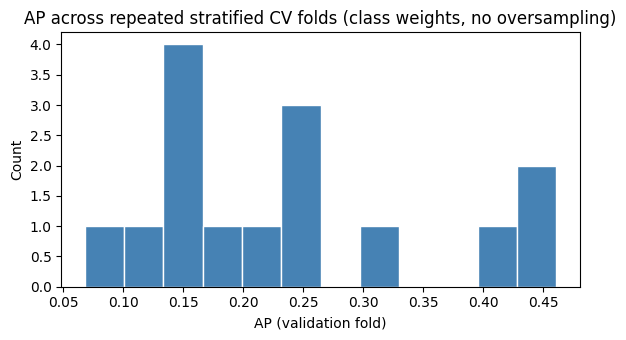

In [5]:
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_score, RepeatedStratifiedKFold

pipe_lr_cv = LogisticRegression(
    max_iter=5000,
    class_weight="balanced",
    random_state=42,
    solver="lbfgs",
)
# Match GridSearchCV: 5 stratified folds
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
pr_5 = cross_val_score(pipe_lr_cv, X_train_cv, y_train_cv, cv=skf, scoring="average_precision", n_jobs=-1)
f1_5 = cross_val_score(pipe_lr_cv, X_train_cv, y_train_cv, cv=skf, scoring="f1", n_jobs=-1)
print(
    "Stratified 5-fold (class weights, no oversampling):\n"
    f"  AP: {pr_5.mean():.4f} ± {pr_5.std():.4f}  | per-fold: {np.round(pr_5, 4)}\n"
    f"  F1: {f1_5.mean():.4f} ± {f1_5.std():.4f}  | per-fold: {np.round(f1_5, 4)}"
)

# Richer distribution: 5 folds × 3 repeats
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
pr_rep = cross_val_score(pipe_lr_cv, X_train_cv, y_train_cv, cv=rskf, scoring="average_precision", n_jobs=-1)
print(
    f"\nRepeated Stratified CV (5×3={len(pr_rep)} scores): "
    f"AP mean={pr_rep.mean():.4f} ± {pr_rep.std():.4f} "
    f"(min={pr_rep.min():.4f}, max={pr_rep.max():.4f})"
)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(pr_rep, bins=12, color="steelblue", edgecolor="white")
ax.set_xlabel("AP (validation fold)")
ax.set_ylabel("Count")
ax.set_title("AP across repeated stratified CV folds (class weights, no oversampling)")
plt.tight_layout()
plt.show()


## 3. Logistic Regression + GridSearchCV

We tune regularization (C, penalty) and use **class_weight='balanced'** for the imbalanced target. After fitting, displaying the GridSearchCV object shows the pipeline flowchart in Jupyter.

In [6]:
param_grid_lr = [
    {"C": [0.01, 0.1, 1.0, 10.0, 100.0], "penalty": ["l2"], "solver": ["lbfgs"], "max_iter": [2000]},
    {"C": [0.01, 0.1, 1.0, 10.0, 100.0], "penalty": ["l1"], "solver": ["liblinear"], "max_iter": [2000]},
]
grid_lr = GridSearchCV(
    estimator=LogisticRegression(class_weight="balanced", random_state=42),
    param_grid=param_grid_lr,
    scoring=GRID_SCORING,
    cv=cv,
    n_jobs=-1,
    verbose=0,
)

grid_lr.fit(X_train, y_train)
print("Best params:", grid_lr.best_params_)
print("Best CV", GRID_SCORING, ":", round(grid_lr.best_score_, 4))


Best params: {'C': 100.0, 'max_iter': 2000, 'penalty': 'l1', 'solver': 'liblinear'}
Best CV average_precision : 0.2655


In [7]:
# Display fitted GridSearchCV (flowchart of the best pipeline in Jupyter)
display(grid_lr)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=LogisticRegression(class_weight='balanced',
                                          random_state=42),
             n_jobs=-1,
             param_grid=[{'C': [0.01, 0.1, 1.0, 10.0, 100.0],
                          'max_iter': [2000], 'penalty': ['l2'],
                          'solver': ['lbfgs']},
                         {'C': [0.01, 0.1, 1.0, 10.0, 100.0],
                          'max_iter': [2000], 'penalty': ['l1'],
                          'solver': ['liblinear']}],
             scoring='average_precision')

In [8]:
best_lr = grid_lr.best_estimator_
results_list = [evaluate_model("LogisticRegression", best_lr)]

              precision    recall  f1-score   support

           0       0.99      0.92      0.95      1528
           1       0.12      0.64      0.21        28

    accuracy                           0.91      1556
   macro avg       0.56      0.78      0.58      1556
weighted avg       0.98      0.91      0.94      1556

ROC-AUC: 0.8318296559461481 | PR-AUC: 0.3430566426131075 | NPV: 0.9929 (TN/(TN+FN)=1402/1412)


### 3.1 Logistic Regression – CV results (top 5 by F1)

View GridSearchCV `cv_results_` to see how different hyperparameters performed.

In [9]:
cv_res_lr = pd.DataFrame(grid_lr.cv_results_)
cols = [
    c for c in cv_res_lr.columns if c.startswith("param_") or c == "mean_test_score"
]
display(cv_res_lr[cols].sort_values("mean_test_score", ascending=False).head())

,param_C,param_max_iter,param_penalty,param_solver,mean_test_score
9,100.0,2000,l1,liblinear,0.265508
6,0.1,2000,l1,liblinear,0.265228
1,0.1,2000,l2,lbfgs,0.260834
8,10.0,2000,l1,liblinear,0.260052
2,1.0,2000,l2,lbfgs,0.259646


## 4. Decision Tree + GridSearchCV

Tune tree depth, min_samples_split, min_samples_leaf, and criterion. After fitting, display the grid to see the pipeline flowchart.

In [10]:
param_grid_dt = {
    "max_depth": [3, 5, 7, 10, 15, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5],
    "criterion": ["gini", "entropy"],
    "max_features": [None, "sqrt"],
}
grid_dt = GridSearchCV(
    estimator=DecisionTreeClassifier(class_weight="balanced", random_state=42),
    param_grid=param_grid_dt,
    scoring=GRID_SCORING,
    cv=cv,
    n_jobs=-1,
    verbose=0,
)

grid_dt.fit(X_train, y_train)
print("Best params:", grid_dt.best_params_)
print("Best CV", GRID_SCORING, ":", round(grid_dt.best_score_, 4))


Best params: {'criterion': 'entropy', 'max_depth': 15, 'max_features': None, 'min_samples_leaf': 5, 'min_samples_split': 2}
Best CV average_precision : 0.2762


In [11]:
# Display fitted GridSearchCV (flowchart)
display(grid_dt)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=DecisionTreeClassifier(class_weight='balanced',
                                              random_state=42),
             n_jobs=-1,
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [3, 5, 7, 10, 15, None],
                         'max_features': [None, 'sqrt'],
                         'min_samples_leaf': [1, 2, 5],
                         'min_samples_split': [2, 5, 10]},
             scoring='average_precision')

In [12]:
best_dt = grid_dt.best_estimator_
results_list.append(evaluate_model("DecisionTree", best_dt))

              precision    recall  f1-score   support

           0       0.99      0.97      0.98      1528
           1       0.21      0.43      0.28        28

    accuracy                           0.96      1556
   macro avg       0.60      0.70      0.63      1556
weighted avg       0.98      0.96      0.97      1556

ROC-AUC: 0.7009396035901272 | PR-AUC: 0.1377668224759019 | NPV: 0.9893 (TN/(TN+FN)=1482/1498)


### 4.1 Decision Tree: Visualize the Fitted Tree

Plot the best decision tree (limited depth for readability). Feature names from preprocessing are used for labels.

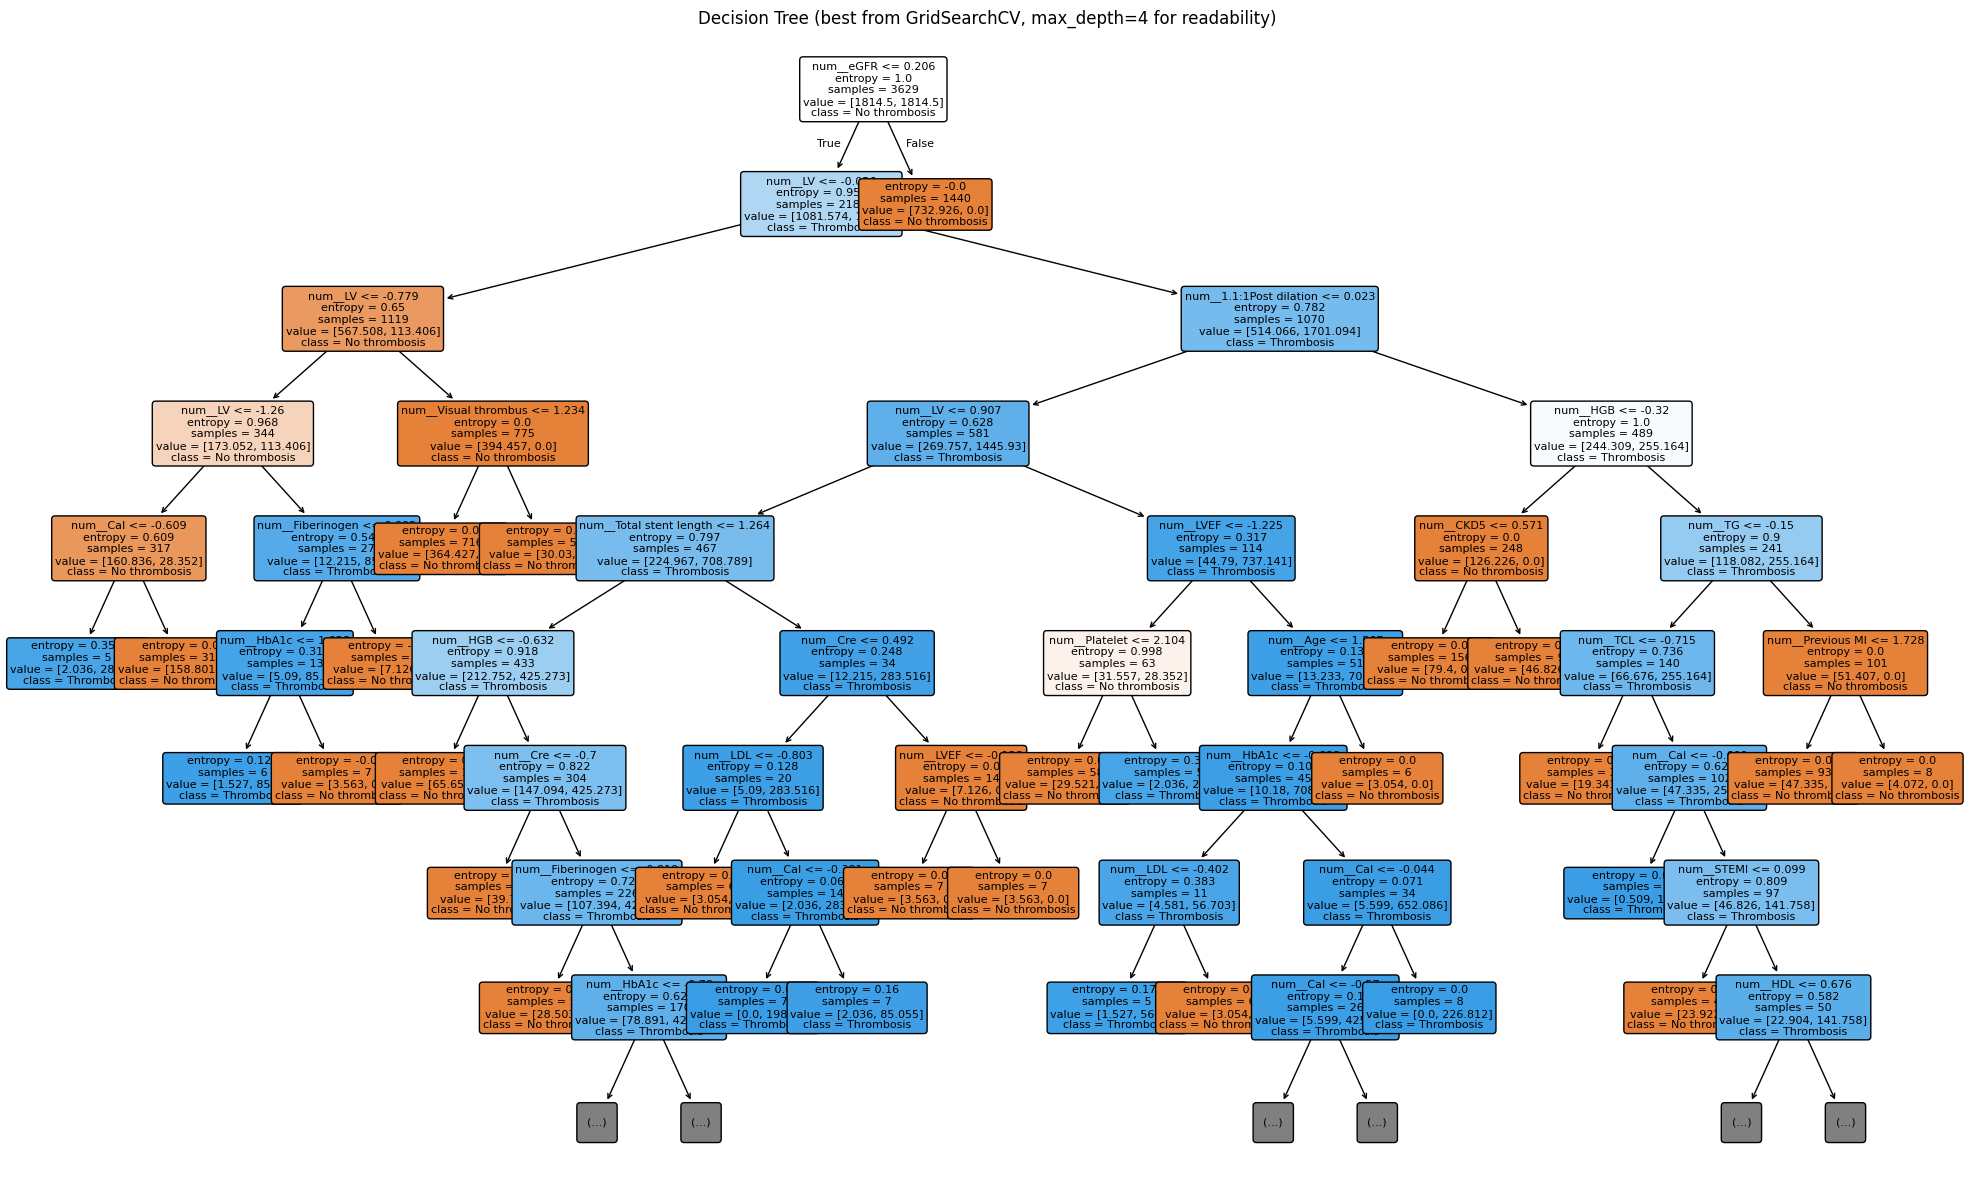

Saved: decision_tree_plot.png


In [13]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(20, 12))
plot_tree(
    best_dt,
    max_depth=8,
    feature_names=feature_names,
    class_names=["No thrombosis", "Thrombosis"],
    filled=True,
    rounded=True,
    ax=ax,
    fontsize=8,
)
ax.set_title("Decision Tree (best from GridSearchCV, max_depth=4 for readability)")
plt.tight_layout()
plt.savefig(
    os.path.join(RESULT_DIR, "decision_tree_plot.png"), dpi=150, bbox_inches="tight"
)
plt.show()
print("Saved: decision_tree_plot.png")

## 5. Random Forest + GridSearchCV

Tune n_estimators, max_depth, and min_samples_leaf. Display the fitted grid for the pipeline flowchart.

In [14]:
param_grid_rf = {
    "n_estimators": [200, 400, 800],
    "max_depth": [5, 10, 20, None],
    "min_samples_leaf": [1, 2, 5],
    "max_features": ["sqrt", 0.5],
}
grid_rf = GridSearchCV(
    estimator=RandomForestClassifier(class_weight="balanced", random_state=42),
    param_grid=param_grid_rf,
    scoring=GRID_SCORING,
    cv=cv,
    n_jobs=-1,
    verbose=0,
)

grid_rf.fit(X_train, y_train)
print("Best params:", grid_rf.best_params_)
print("Best CV", GRID_SCORING, ":", round(grid_rf.best_score_, 4))


Best params: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'n_estimators': 400}
Best CV average_precision : 0.496


In [15]:
# Display fitted GridSearchCV (flowchart)
display(grid_rf)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=RandomForestClassifier(class_weight='balanced',
                                              random_state=42),
             n_jobs=-1,
             param_grid={'max_depth': [5, 10, 20, None],
                         'max_features': ['sqrt', 0.5],
                         'min_samples_leaf': [1, 2, 5],
                         'n_estimators': [200, 400, 800]},
             scoring='average_precision')

In [16]:
best_rf = grid_rf.best_estimator_
results_list.append(evaluate_model("RandomForest", best_rf))

              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1528
           1       0.00      0.00      0.00        28

    accuracy                           0.98      1556
   macro avg       0.49      0.50      0.50      1556
weighted avg       0.96      0.98      0.97      1556

ROC-AUC: 0.9287116679132386 | PR-AUC: 0.4873731711904865 | NPV: 0.982 (TN/(TN+FN)=1528/1556)


## 5b. Gaussian Naive Bayes + GridSearchCV

Gaussian NB is fast and works well with balanced or moderately imbalanced data. We tune `var_smoothing` for stability.

In [17]:
param_grid_gnb = {"var_smoothing": np.logspace(-12, -6, 13)}
grid_gnb = GridSearchCV(
    estimator=GaussianNB(),
    param_grid=param_grid_gnb,
    scoring=GRID_SCORING,
    cv=cv,
    n_jobs=-1,
    verbose=0,
)
grid_gnb.fit(X_train, y_train)
print("Best params:", grid_gnb.best_params_)
print("Best CV", GRID_SCORING, ":", round(grid_gnb.best_score_, 4))


Best params: {'var_smoothing': np.float64(1e-06)}
Best CV average_precision : 0.0337


In [18]:
display(grid_gnb)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=GaussianNB(), n_jobs=-1,
             param_grid={'var_smoothing': array([1.00000000e-12, 3.16227766e-12, 1.00000000e-11, 3.16227766e-11,
       1.00000000e-10, 3.16227766e-10, 1.00000000e-09, 3.16227766e-09,
       1.00000000e-08, 3.16227766e-08, 1.00000000e-07, 3.16227766e-07,
       1.00000000e-06])},
             scoring='average_precision')

In [19]:
best_gnb = grid_gnb.best_estimator_
results_list.append(evaluate_model("GaussianNB", best_gnb))

              precision    recall  f1-score   support

           0       0.99      0.19      0.31      1528
           1       0.02      0.86      0.04        28

    accuracy                           0.20      1556
   macro avg       0.50      0.52      0.17      1556
weighted avg       0.97      0.20      0.31      1556

ROC-AUC: 0.7493104899027674 | PR-AUC: 0.05643275509390651 | NPV: 0.9861 (TN/(TN+FN)=283/287)


## 5c. CatBoost + GridSearchCV

CatBoost handles categorical features natively; here we use the preprocessed numeric matrix.

In [20]:
# Wrapper so CatBoost works with GridSearchCV
class CatBoostClassifierWrapper(BaseEstimator, ClassifierMixin):
    def __init__(self, **kwargs):
        self.catboost_ = CatBoostClassifier(**kwargs)

    def get_params(self, deep=True):
        return self.catboost_.get_params(deep=deep)

    def set_params(self, **params):
        self.catboost_.set_params(**params)
        return self

    def fit(self, X, y, **fit_params):
        self.catboost_.fit(X, y, **fit_params)
        return self

    def predict(self, X):
        return self.catboost_.predict(X)

    def predict_proba(self, X):
        return self.catboost_.predict_proba(X)

In [21]:
param_grid_cat = {
    "depth": [4, 6, 8],
    "learning_rate": [0.03, 0.05, 0.1],
    "iterations": [200, 400],
    "l2_leaf_reg": [1, 3, 5],
}
grid_cat = GridSearchCV(
    estimator=CatBoostClassifierWrapper(
        random_state=42,
        verbose=0,
        auto_class_weights="Balanced",
        eval_metric="PRAUC",
    ),
    param_grid=param_grid_cat,
    scoring=GRID_SCORING,
    cv=cv,
    n_jobs=-1,
    verbose=0,
)
grid_cat.fit(X_train, y_train)
print("Best params:", grid_cat.best_params_)
print("Best CV", GRID_SCORING, ":", round(grid_cat.best_score_, 4))
best_cat = grid_cat.best_estimator_
display(grid_cat)
results_list.append(evaluate_model("CatBoost", best_cat))


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:960: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 949, in _score
    scores = scorer(estimator, X_test, y_test, **score_params)
  File "/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_scorer.py", line 288, in __call__
    return self._score(partial(_cached_call, None), estimator, X, y_true, **_kwargs)
           ~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_scorer.py", line 380, in _score
    y_pred = method_caller(
        estimator,
    ...<2 lines>...
        pos_label=pos_label,
    )
  File "/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_scorer.py", line 90, in _cached_call
    result, _ = _get

Best params: {'depth': 4, 'iterations': 200, 'l2_leaf_reg': 1, 'learning_rate': 0.03}
Best CV average_precision : nan


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=CatBoostClassifierWrapper(auto_class_weights='Balanced',
                                                 eval_metric='PRAUC',
                                                 random_state=42, verbose=0),
             n_jobs=-1,
             param_grid={'depth': [4, 6, 8], 'iterations': [200, 400],
                         'l2_leaf_reg': [1, 3, 5],
                         'learning_rate': [0.03, 0.05, 0.1]},
             scoring='average_precision')

              precision    recall  f1-score   support

           0       0.99      0.98      0.98      1528
           1       0.31      0.61      0.41        28

    accuracy                           0.97      1556
   macro avg       0.65      0.79      0.70      1556
weighted avg       0.98      0.97      0.97      1556

ROC-AUC: 0.9102701944652206 | PR-AUC: 0.4942184439177125 | NPV: 0.9927 (TN/(TN+FN)=1490/1501)


## 5d. XGBoost + GridSearchCV

Gradient boosting; often strong on tabular data.

In [22]:
scale_pos_weight = (y_train == 0).sum() / max((y_train == 1).sum(), 1)
param_grid_xgb = {
    "max_depth": [3, 5, 7],
    "learning_rate": [0.03, 0.05, 0.1],
    "n_estimators": [200, 400],
    "min_child_weight": [1, 3],
    "subsample": [0.8, 1.0],
}
grid_xgb = GridSearchCV(
    estimator=XGBClassifier(
        random_state=42,
        use_label_encoder=False,
        eval_metric="aucpr",
        scale_pos_weight=scale_pos_weight,
    ),
    param_grid=param_grid_xgb,
    scoring=GRID_SCORING,
    cv=cv,
    n_jobs=-1,
    verbose=0,
)
grid_xgb.fit(X_train, y_train)
print("Best params:", grid_xgb.best_params_)
print("Best CV", GRID_SCORING, ":", round(grid_xgb.best_score_, 4))
best_xgb = grid_xgb.best_estimator_
display(grid_xgb)
results_list.append(evaluate_model("XGBoost", best_xgb))


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [16:04:42] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [16:04:42] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [16:04:42] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [16:04:42] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:

Best params: {'learning_rate': 0.1, 'max_depth': 5, 'min_child_weight': 1, 'n_estimators': 400, 'subsample': 1.0}
Best CV average_precision : 0.6714


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=True,
                                     eval_metric='aucpr', feature_types=None,
                                     feature_weights=None, gamma=None,
                                     grow_pol...
                                     max_delta_step=None, max_depth=None,
                                     max_leaves=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     multi_strategy=None, n_estimators=None,
                                     n_jobs=None, num_parallel_tree=None, ...),
             n_jobs=-1,
             param_grid={'learning_rate': [0.03, 0.05, 0.1],
                         'max_depth': [3, 5, 7], 'min_child_weight': [1, 3],
                         'n_estimators': [200, 400], 'subsample': [0.8, 1.0]},
             scoring='average_precision')

              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1528
           1       1.00      0.36      0.53        28

    accuracy                           0.99      1556
   macro avg       0.99      0.68      0.76      1556
weighted avg       0.99      0.99      0.99      1556

ROC-AUC: 0.9418474195961106 | PR-AUC: 0.592415269162316 | NPV: 0.9884 (TN/(TN+FN)=1528/1546)


## 5e. LightGBM + GridSearchCV

LightGBM is fast and often performs well on tabular data.

In [23]:
param_grid_lgb = {
    "max_depth": [3, 5, 7],
    "learning_rate": [0.03, 0.05, 0.1],
    "n_estimators": [200, 400],
    "min_child_samples": [10, 20, 40],
    "num_leaves": [15, 31],
}
grid_lgb = GridSearchCV(
    estimator=LGBMClassifier(
        random_state=42,
        class_weight="balanced",
        metric="average_precision",
        verbosity=-1,
    ),
    param_grid=param_grid_lgb,
    scoring=GRID_SCORING,
    cv=cv,
    n_jobs=-1,
    verbose=0,
)
grid_lgb.fit(X_train, y_train)
print("Best params:", grid_lgb.best_params_)
print("Best CV", GRID_SCORING, ":", round(grid_lgb.best_score_, 4))
best_lgb = grid_lgb.best_estimator_
display(grid_lgb)
results_list.append(evaluate_model("LightGBM", best_lgb))


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

Best params: {'learning_rate': 0.1, 'max_depth': 5, 'min_child_samples': 40, 'n_estimators': 400, 'num_leaves': 15}
Best CV average_precision : 0.7067


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=LGBMClassifier(class_weight='balanced',
                                      metric='average_precision',
                                      random_state=42, verbosity=-1),
             n_jobs=-1,
             param_grid={'learning_rate': [0.03, 0.05, 0.1],
                         'max_depth': [3, 5, 7],
                         'min_child_samples': [10, 20, 40],
                         'n_estimators': [200, 400], 'num_leaves': [15, 31]},
             scoring='average_precision')

              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1528
           1       1.00      0.29      0.44        28

    accuracy                           0.99      1556
   macro avg       0.99      0.64      0.72      1556
weighted avg       0.99      0.99      0.98      1556

ROC-AUC: 0.9404450261780104 | PR-AUC: 0.6675423700663407 | NPV: 0.9871 (TN/(TN+FN)=1528/1548)


## 6. ROC and Precision-Recall Curves

Compare all three models on ROC and PR curves (PR is more informative for imbalanced data).

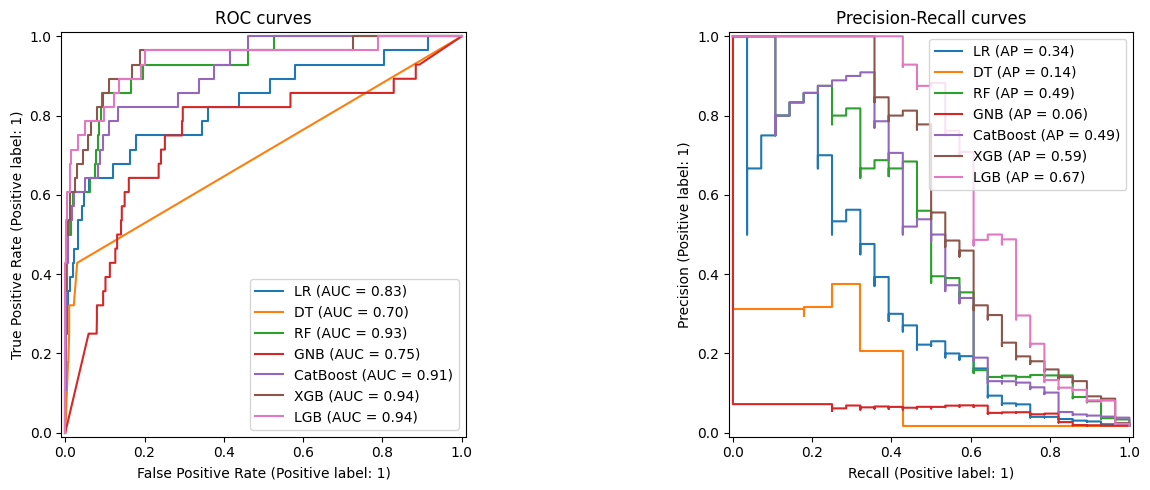

Saved: roc_pr_curves.png


In [24]:
curve_models = [
    ("LR", best_lr),
    ("DT", best_dt),
    ("RF", best_rf),
    ("GNB", best_gnb),
    ("CatBoost", best_cat),
    ("XGB", best_xgb),
    ("LGB", best_lgb),
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, model in curve_models:
    y_prob = model.predict_proba(X_test)[:, 1]
    RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[0], name=name)
axes[0].set_title("ROC curves")
axes[0].legend()

for name, model in curve_models:
    y_prob = model.predict_proba(X_test)[:, 1]
    PrecisionRecallDisplay.from_predictions(y_test, y_prob, ax=axes[1], name=name)
axes[1].set_title("Precision-Recall curves")
axes[1].legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULT_DIR, "roc_pr_curves.png"), dpi=150, bbox_inches="tight")
plt.show()
print("Saved: roc_pr_curves.png")

## 7. Confusion Matrices

Heatmaps of confusion matrices for each model on the test set.

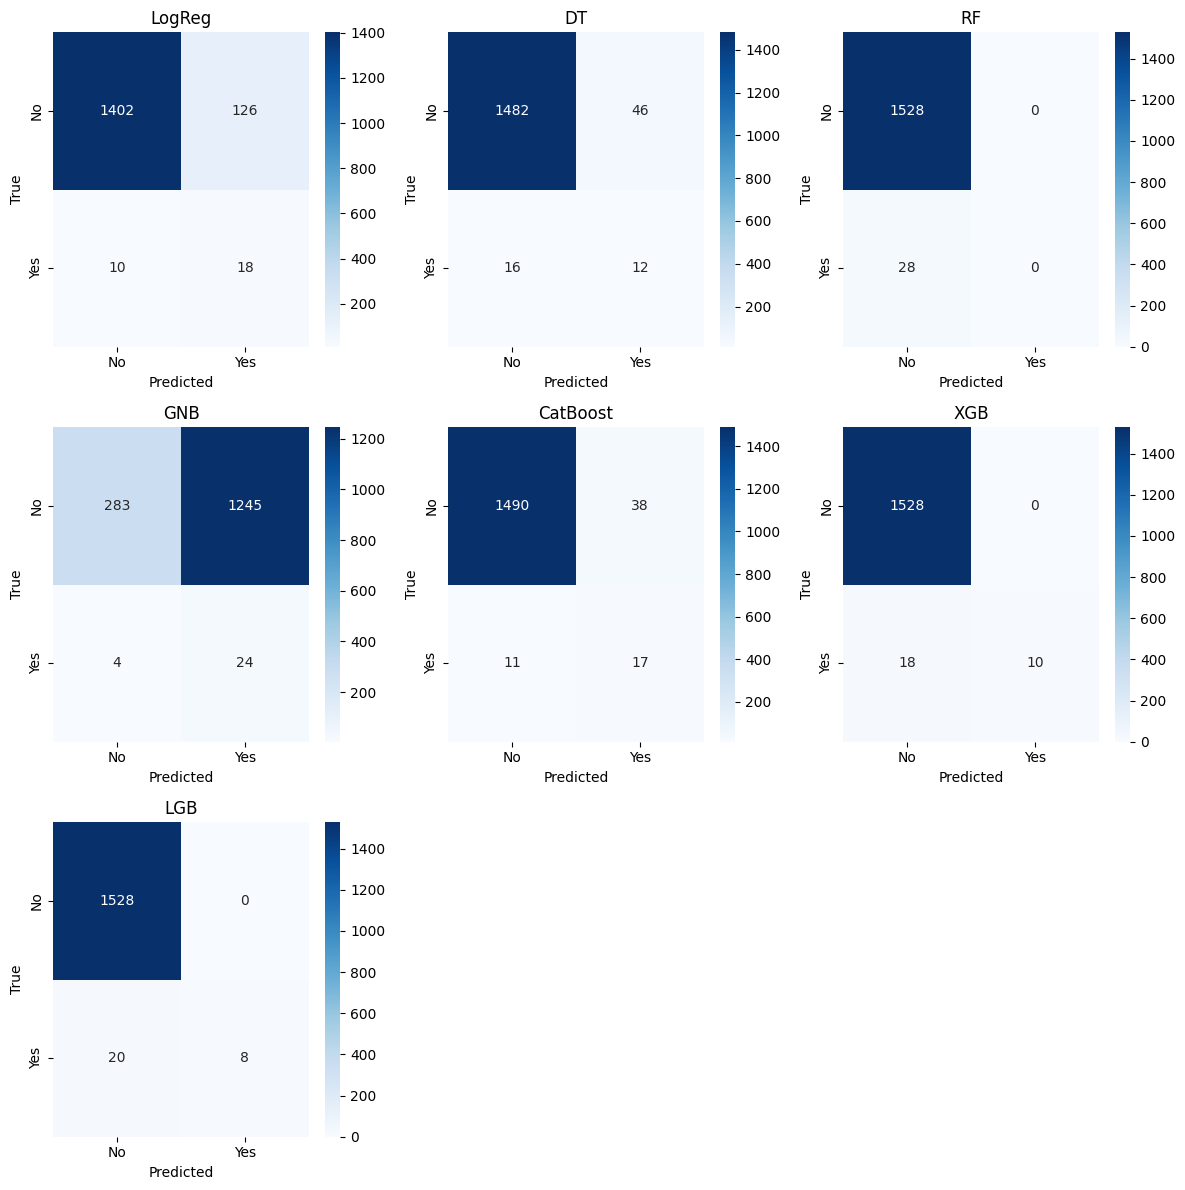

Saved: confusion_matrices.png


In [25]:
import seaborn as sns

cm_models = [
    ("LogReg", best_lr),
    ("DT", best_dt),
    ("RF", best_rf),
    ("GNB", best_gnb),
    ("CatBoost", best_cat),
    ("XGB", best_xgb),
    ("LGB", best_lgb),
]
n_models = len(cm_models)
n_cols = 3
n_rows = (n_models + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows))
axes = axes.flatten() if n_models > 1 else [axes]
for ax, (name, model) in zip(axes, cm_models):
    cm = confusion_matrix(y_test, model.predict(X_test))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        ax=ax,
        cmap="Blues",
        xticklabels=["No", "Yes"],
        yticklabels=["No", "Yes"],
    )
    ax.set_title(name)
    ax.set_ylabel("True")
    ax.set_xlabel("Predicted")
for ax in axes[len(cm_models) :]:
    ax.axis("off")
plt.tight_layout()
plt.savefig(
    os.path.join(RESULT_DIR, "confusion_matrices.png"), dpi=150, bbox_inches="tight"
)
plt.show()
print("Saved: confusion_matrices.png")

## 8. Threshold Analysis (Optional)

For the best model by F1, we can sweep the decision threshold and report precision, recall, and F1. This helps choose a threshold if you want to favor recall over precision or vice versa.

In [26]:
# Pick best model by test F1 for threshold analysis
threshold_candidates = [
    ("LR", best_lr),
    ("DT", best_dt),
    ("RF", best_rf),
    ("GNB", best_gnb),
    ("CatBoost", best_cat),
    ("XGB", best_xgb),
    ("LGB", best_lgb),
]
best_by_f1 = max(
    threshold_candidates, key=lambda t: f1_score(y_test, t[1].predict(X_test))
)
name_best, model_best = best_by_f1
y_prob_best = model_best.predict_proba(X_test)[:, 1]

thresholds = np.arange(0.1, 0.95, 0.05)
rows = []
for t in thresholds:
    y_pt = (y_prob_best >= t).astype(int)
    rows.append(
        {
            "threshold": t,
            "precision": precision_score(y_test, y_pt, zero_division=0),
            "recall": recall_score(y_test, y_pt, zero_division=0),
            "f1": f1_score(y_test, y_pt, zero_division=0),
        }
    )
threshold_df = pd.DataFrame(rows)
print(f"Threshold analysis for best model ({name_best}):")
display(threshold_df)

Threshold analysis for best model (XGB):


,threshold,precision,recall,f1
0,0.10,0.517241,0.535714,0.526316
1,0.15,0.608696,0.500000,0.549020
2,0.20,0.700000,0.500000,0.583333
3,0.25,0.736842,0.500000,0.595745
4,0.30,0.833333,0.357143,0.500000
5,0.35,0.909091,0.357143,0.512821
6,0.40,1.000000,0.357143,0.526316
7,0.45,1.000000,0.357143,0.526316
8,0.50,1.000000,0.357143,0.526316
9,0.55,1.000000,0.321429,0.486486


## 9. Results Summary and Saving Artifacts

Summarize test metrics for all models and save best estimators and results table.

In [27]:
results_df = pd.DataFrame(results_list)
results_df = results_df.reindex(
    columns=["model", "accuracy", "f1", "recall", "precision", "roc_auc", "pr_auc"]
)
print("Test set metrics:")
display(results_df)

results_df.to_csv(os.path.join(RESULT_DIR, "test_metrics.csv"), index=False)
threshold_df.to_csv(os.path.join(RESULT_DIR, "threshold_analysis.csv"), index=False)

joblib.dump(best_lr, os.path.join(RESULT_DIR, "best_logistic.joblib"))
joblib.dump(best_dt, os.path.join(RESULT_DIR, "best_decision_tree.joblib"))
joblib.dump(best_rf, os.path.join(RESULT_DIR, "best_random_forest.joblib"))
joblib.dump(best_gnb, os.path.join(RESULT_DIR, "best_gaussian_nb.joblib"))
joblib.dump(best_cat, os.path.join(RESULT_DIR, "best_catboost.joblib"))
joblib.dump(best_xgb, os.path.join(RESULT_DIR, "best_xgboost.joblib"))
joblib.dump(best_lgb, os.path.join(RESULT_DIR, "best_lightgbm.joblib"))

print("\nSaved to", RESULT_DIR)
for f in sorted(os.listdir(RESULT_DIR)):
    print(" ", f)

Test set metrics:


,model,accuracy,f1,recall,precision,roc_auc,pr_auc
0,LogisticRegression,0.912596,0.209302,0.642857,0.125000,0.831830,0.343057
1,DecisionTree,0.960154,0.279070,0.428571,0.206897,0.700940,0.137767
2,RandomForest,0.982005,0.000000,0.000000,0.000000,0.928712,0.487373
3,GaussianNB,0.197301,0.037008,0.857143,0.018913,0.749310,0.056433
4,CatBoost,0.968509,0.409639,0.607143,0.309091,0.910270,0.494218
5,XGBoost,0.988432,0.526316,0.357143,1.000000,0.941847,0.592415
6,LightGBM,0.987147,0.444444,0.285714,1.000000,0.940445,0.667542



Saved to /kaggle/working/modeling_without_leakage
  best_catboost.joblib
  best_decision_tree.joblib
  best_gaussian_nb.joblib
  best_lightgbm.joblib
  best_logistic.joblib
  best_random_forest.joblib
  best_xgboost.joblib
  confusion_matrices.png
  decision_tree_plot.png
  roc_pr_curves.png
  test_metrics.csv
  threshold_analysis.csv


## 10. Summary

- **Data**: Loaded from `data/processed/` (`../preprocessing/preprocessing.ipynb`); **`Time since stent implantation` removed** after load (§1).
- **Models**: Logistic Regression, Decision Tree, Random Forest, Gaussian NB, CatBoost, XGBoost, LightGBM (with **GridSearchCV** where applicable); each fitted grid is **displayed** so Jupyter shows the pipeline flowchart.
- **Imbalance**: `class_weight='balanced'` (and scale_pos_weight / auto_class_weights where supported), no oversampling, and metrics: F1, ROC-AUC, AP, recall.
- **Visuals**: Decision tree plot, ROC/PR curves, confusion matrices, threshold table.
- **Artifacts**: Best estimators and metrics saved under `data/result/modeling_no_time_since_stent/`.

For inference on new data: preprocess with `preprocessor.joblib` and `scaler.joblib`, **drop the same column(s) from the scaled matrix** (match `feature_names.csv` order), then call `best_*.predict(X)` or `best_*.predict_proba(X)`.

**Anti-leakage (this code, not yet the stored outputs):** raw `VLST.csv`; drop IDs + WBC + TSSI; quantize Cre/CaI/Fiberinogen/Fast-Glu; stent `min_count=30` fit on the training split only; scaler/OHE fit on train only. Re-run to refresh metrics. Previous Table S-TSSI numbers remain in the executed outputs until then.
